# 08 — Probabilistic Machine Learning

## Objective

This notebook extends the deterministic machine-learning analysis by introducing probabilistic prediction.

Previous models produced point estimates of acceleration,

$$
\hat{\ddot{x}}.
$$

A probabilistic model instead aims to describe uncertainty in the prediction through a conditional distribution,

$$
p(\ddot{x}\mid x,\dot{x},F).
$$

The main objectives are to:

- predict the expected acceleration,
- quantify predictive uncertainty,
- construct uncertainty intervals,
- examine how uncertainty changes across the held-out time interval,
- compare probabilistic predictions with the deterministic machine-learning baseline.

Gaussian Process Regression is used as the first probabilistic model because it provides both a predictive mean and a predictive standard deviation.

This probabilistic analysis provides a bridge between deterministic machine learning and the broader Monte Carlo uncertainty-quantification framework developed later in the project.

In [1]:
# NOTEBOOK SETUP

from pathlib import Path
import sys


# Identify the project root directory.
PROJECT_ROOT = Path.cwd().parent


# Add the project root to Python's import path.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )


# Standard scientific Python libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Scikit-learn preprocessing.
from sklearn.preprocessing import StandardScaler


# Gaussian Process tools.
from sklearn.gaussian_process import GaussianProcessRegressor

from sklearn.gaussian_process.kernels import (
    ConstantKernel,
    RBF,
    WhiteKernel,
)


# Performance metrics.
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)


# Project utilities.
from src.utils import (
    data_path,
    results_path,
    figures_path,
    ensure_directory,
)

In [2]:
# LOAD DATA AND PREPARE GAUSSIAN-PROCESS DATA

baseline_data_path = (
    data_path("raw")
    / "deterministic_baseline.csv"
)

baseline_data = pd.read_csv(
    baseline_data_path
)


# Build the input matrix:
#
# X = [displacement, velocity, excitation]
gp_input = np.column_stack(
    (
        baseline_data["displacement"].to_numpy(),
        baseline_data["velocity"].to_numpy(),
        baseline_data["excitation"].to_numpy(),
    )
)


# Prediction target:
# acceleration
gp_target = baseline_data[
    "acceleration"
].to_numpy()


# Time vector.
gp_time = baseline_data[
    "time"
].to_numpy()



# TIME-AWARE 80/20 SPLIT
train_fraction = 0.80

split_index = int(
    train_fraction
    * len(gp_input)
)


X_train_full = gp_input[
    :split_index
]

y_train_full = gp_target[
    :split_index
]

time_train_full = gp_time[
    :split_index
]


X_test_gp = gp_input[
    split_index:
]

y_test_gp = gp_target[
    split_index:
]

time_test_gp = gp_time[
    split_index:
]



# SUBSAMPLE THE TRAINING DATA

# A standard Gaussian Process becomes expensive when the
# number of training samples is large.
#
# We therefore select evenly spaced samples from the original
# training interval instead of randomly sampling them.
#
# This preserves coverage across the full training period.

number_of_gp_training_samples = 800

gp_training_indices = np.linspace(
    0,
    len(X_train_full) - 1,
    number_of_gp_training_samples,
    dtype=int,
)


X_train_gp = X_train_full[
    gp_training_indices
]

y_train_gp = y_train_full[
    gp_training_indices
]

time_train_gp = time_train_full[
    gp_training_indices
]


print(
    f"Original training samples: "
    f"{len(X_train_full)}"
)

print(
    f"GP training samples:       "
    f"{len(X_train_gp)}"
)

print(
    f"GP testing samples:        "
    f"{len(X_test_gp)}"
)

print()

print(
    f"GP training time range: "
    f"{time_train_gp[0]:.4f} s "
    f"to {time_train_gp[-1]:.4f} s"
)

print(
    f"GP testing time range:  "
    f"{time_test_gp[0]:.4f} s "
    f"to {time_test_gp[-1]:.4f} s"
)

Original training samples: 16000
GP training samples:       800
GP testing samples:        4001

GP training time range: 0.0000 s to 1.5999 s
GP testing time range:  1.6000 s to 2.0000 s


In [3]:
# STANDARDIZE INPUTS AND TARGET

# Create separate scalers for:
#
# - the three input variables,
# - the acceleration target.
#
# The scalers are fitted ONLY using the GP training data.
# This prevents information from the held-out test set
# from leaking into model training.

gp_input_scaler = StandardScaler()

gp_target_scaler = StandardScaler()



# STANDARDIZE INPUT VARIABLES

X_train_gp_scaled = gp_input_scaler.fit_transform(
    X_train_gp
)

X_test_gp_scaled = gp_input_scaler.transform(
    X_test_gp
)



# STANDARDIZE TARGET

# StandardScaler expects a two-dimensional array,
# therefore reshape acceleration temporarily.

y_train_gp_scaled = (
    gp_target_scaler
    .fit_transform(
        y_train_gp.reshape(-1, 1)
    )
    .ravel()
)


# Display the resulting training statistics.
print("Scaled GP training input means:")

print(
    np.mean(
        X_train_gp_scaled,
        axis=0,
    )
)

print()

print("Scaled GP training input standard deviations:")

print(
    np.std(
        X_train_gp_scaled,
        axis=0,
    )
)

print()

print(
    f"Scaled GP target mean: "
    f"{np.mean(y_train_gp_scaled):.12e}"
)

print(
    f"Scaled GP target standard deviation: "
    f"{np.std(y_train_gp_scaled):.12f}"
)

Scaled GP training input means:
[ 6.38378239e-17 -6.35602682e-17  1.75692794e-16]

Scaled GP training input standard deviations:
[1. 1. 1.]

Scaled GP target mean: -1.776356839400e-17
Scaled GP target standard deviation: 1.000000000000


In [4]:
# DEFINE AND TRAIN THE GAUSSIAN PROCESS

# ConstantKernel controls the overall magnitude of the
# Gaussian Process covariance.
#
# RBF gives the model a smooth nonlinear relationship.
# We provide one length scale for each input:
#
# [displacement, velocity, excitation]
#
# WhiteKernel allows the model to estimate a small
# observation-noise contribution.

gp_kernel = (
    ConstantKernel(
        constant_value=1.0,
        constant_value_bounds=(1e-3, 1e3),
    )
    *
    RBF(
        length_scale=[
            1.0,
            1.0,
            1.0,
        ],
        length_scale_bounds=(1e-2, 1e3),
    )
    +
    WhiteKernel(
        noise_level=1e-6,
        noise_level_bounds=(1e-10, 1e-1),
    )
)


# Create the Gaussian Process model.
#
# normalize_y=False because we already standardized
# the target manually.
#
# n_restarts_optimizer=2 gives the kernel optimizer
# additional starting points without making the experiment
# unnecessarily expensive.

gaussian_process_model = GaussianProcessRegressor(
    kernel=gp_kernel,
    alpha=0.0,
    normalize_y=False,
    n_restarts_optimizer=2,
    random_state=9512,
)


# Train the Gaussian Process.
gaussian_process_model.fit(
    X_train_gp_scaled,
    y_train_gp_scaled,
)


# Display the optimized kernel.
print(
    "Optimized Gaussian Process kernel:"
)

print(
    gaussian_process_model.kernel_
)

print()

print(
    "Log-marginal likelihood:"
)

print(
    f"{gaussian_process_model.log_marginal_likelihood_value_:.6f}"
)

c:\Users\ahmed\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 18 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
c:\Users\ahmed\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 9 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


Optimized Gaussian Process kernel:
31.6**2 * RBF(length_scale=[72.7, 1e+03, 377]) + WhiteKernel(noise_level=1e-10)

Log-marginal likelihood:
8354.497215


c:\Users\ahmed\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\ahmed\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\ahmed\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  wa

In [5]:
# GAUSSIAN PROCESS PROBABILISTIC PREDICTION


# Ask the Gaussian Process for:
#
# 1. the predictive mean,
# 2. the predictive standard deviation.
#
# Both are initially returned in standardized target units.

(
    gp_test_mean_scaled,
    gp_test_std_scaled,
) = gaussian_process_model.predict(
    X_test_gp_scaled,
    return_std=True,
)



# TRANSFORM THE PREDICTIVE MEAN BACK TO PHYSICAL UNITS
gp_test_mean = (
    gp_target_scaler
    .inverse_transform(
        gp_test_mean_scaled.reshape(-1, 1)
    )
    .ravel()
)



# TRANSFORM THE STANDARD DEVIATION BACK TO PHYSICAL UNITS

# Standard deviations are scaled only by the target
# standard-deviation factor.
#
# We do NOT add the target mean to a standard deviation.

gp_test_std = (
    gp_test_std_scaled
    * gp_target_scaler.scale_[0]
)



# CONSTRUCT APPROXIMATE 95% PREDICTION INTERVALS

gp_lower_95 = (
    gp_test_mean
    - 1.96 * gp_test_std
)

gp_upper_95 = (
    gp_test_mean
    + 1.96 * gp_test_std
)



# CALCULATE POINT-PREDICTION PERFORMANCE

gp_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_gp,
        gp_test_mean,
    )
)

gp_test_mae = mean_absolute_error(
    y_test_gp,
    gp_test_mean,
)

gp_test_r2 = r2_score(
    y_test_gp,
    gp_test_mean,
)



# CALCULATE UNCERTAINTY STATISTICS

gp_mean_predictive_std = np.mean(
    gp_test_std
)

gp_max_predictive_std = np.max(
    gp_test_std
)


# Fraction of true test values contained inside the
# approximate 95% predictive interval.
gp_coverage_95 = np.mean(
    (y_test_gp >= gp_lower_95)
    &
    (y_test_gp <= gp_upper_95)
)


print(
    f"GP testing RMSE: "
    f"{gp_test_rmse:.12e}"
)

print(
    f"GP testing MAE:  "
    f"{gp_test_mae:.12e}"
)

print(
    f"GP testing R²:   "
    f"{gp_test_r2:.12f}"
)

print()

print(
    f"Mean predictive standard deviation: "
    f"{gp_mean_predictive_std:.12e}"
)

print(
    f"Maximum predictive standard deviation: "
    f"{gp_max_predictive_std:.12e}"
)

print(
    f"95% interval empirical coverage: "
    f"{100 * gp_coverage_95:.4f}%"
)

GP testing RMSE: 1.303546535889e-06
GP testing MAE:  1.104566757868e-06
GP testing R²:   1.000000000000

Mean predictive standard deviation: 3.023500536886e-05
Maximum predictive standard deviation: 3.081073450081e-05
95% interval empirical coverage: 100.0000%


### Gaussian Process Predictive Performance

The Gaussian Process achieved highly accurate predictions on the held-out test interval.

The point-prediction performance was

$$
\mathrm{RMSE}\approx1.30\times10^{-6},
$$

$$
\mathrm{MAE}\approx1.10\times10^{-6},
$$

and

$$
R^2=1.000000.
$$

The mean predictive standard deviation was approximately

$$
3.02\times10^{-5},
$$

with a maximum value of approximately

$$
3.08\times10^{-5}.
$$

The nominal 95% predictive interval contained 100% of the held-out target values.

This indicates that the Gaussian Process provides both highly accurate mean predictions and narrow uncertainty intervals for the deterministic baseline.

However, 100% empirical coverage should not be interpreted automatically as perfect uncertainty calibration. Since the nominal coverage is 95%, the observed 100% coverage suggests that the predictive intervals may be somewhat conservative for this clean deterministic dataset.

The probabilistic calibration will therefore be examined further rather than relying only on point-prediction accuracy.

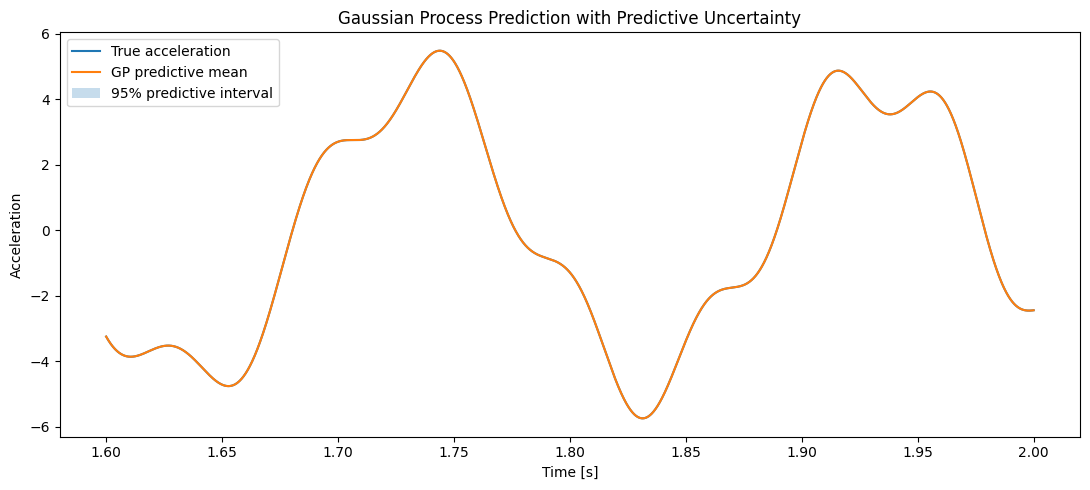

Gaussian Process prediction figure saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\figures\probabilistic_ml\gaussian_process_prediction_interval.png


In [6]:
# PLOT GAUSSIAN PROCESS PREDICTION AND 95% INTERVAL
plt.figure(
    figsize=(11, 5)
)


# True acceleration.
plt.plot(
    time_test_gp,
    y_test_gp,
    label="True acceleration",
)


# Gaussian Process predictive mean.
plt.plot(
    time_test_gp,
    gp_test_mean,
    label="GP predictive mean",
)


# 95% predictive interval.
plt.fill_between(
    time_test_gp,
    gp_lower_95,
    gp_upper_95,
    alpha=0.25,
    label="95% predictive interval",
)


plt.xlabel(
    "Time [s]"
)

plt.ylabel(
    "Acceleration"
)

plt.title(
    "Gaussian Process Prediction with Predictive Uncertainty"
)

plt.legend()

plt.tight_layout()



probabilistic_figure_directory = figures_path(
    "probabilistic_ml"
)

ensure_directory(
    probabilistic_figure_directory
)


gp_prediction_figure_path = (
    probabilistic_figure_directory
    / "gaussian_process_prediction_interval.png"
)


plt.savefig(
    gp_prediction_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "Gaussian Process prediction figure saved to:"
)

print(
    gp_prediction_figure_path
)

### Gaussian Process Prediction with Uncertainty

The Gaussian Process predictive mean follows the true acceleration almost exactly across the held-out test interval.

The 95% predictive interval is extremely narrow relative to the overall acceleration amplitude and is therefore barely visible at the full signal scale.

This agrees with the numerical results:

$$
\mathrm{RMSE}\approx1.30\times10^{-6},
$$

while the mean predictive standard deviation is only approximately

$$
3.02\times10^{-5}.
$$

The probabilistic model therefore expresses high confidence in its predictions for this deterministic baseline.

Because the uncertainty band is difficult to inspect on the full acceleration scale, the predictive standard deviation is examined separately next.

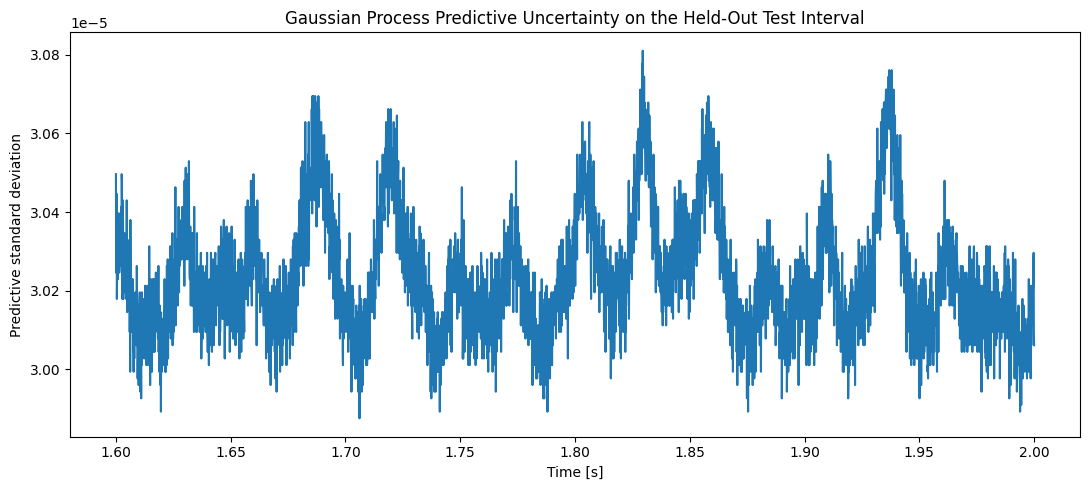

Gaussian Process uncertainty figure saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\figures\probabilistic_ml\gaussian_process_predictive_uncertainty.png


In [7]:
# PLOT PREDICTIVE STANDARD DEVIATION
plt.figure(
    figsize=(11, 5)
)

plt.plot(
    time_test_gp,
    gp_test_std,
)

plt.xlabel(
    "Time [s]"
)

plt.ylabel(
    "Predictive standard deviation"
)

plt.title(
    "Gaussian Process Predictive Uncertainty "
    "on the Held-Out Test Interval"
)

plt.tight_layout()


# Save the uncertainty figure.
gp_uncertainty_figure_path = (
    probabilistic_figure_directory
    / "gaussian_process_predictive_uncertainty.png"
)

plt.savefig(
    gp_uncertainty_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "Gaussian Process uncertainty figure saved to:"
)

print(
    gp_uncertainty_figure_path
)

### Predictive Uncertainty Behaviour

The predictive standard deviation remains very small throughout the held-out interval, with values close to

$$
3\times10^{-5}.
$$

Small variations are present across the trajectory, but the uncertainty remains approximately constant in magnitude.

Because this uncertainty is several orders of magnitude smaller than the overall acceleration range, the 95% predictive interval is not clearly visible in the full-scale acceleration plot.

Similarly, the Gaussian Process predictive mean overlaps almost perfectly with the true acceleration curve. The apparent absence of separate curves in the previous figure therefore reflects the very high prediction accuracy rather than a plotting error.

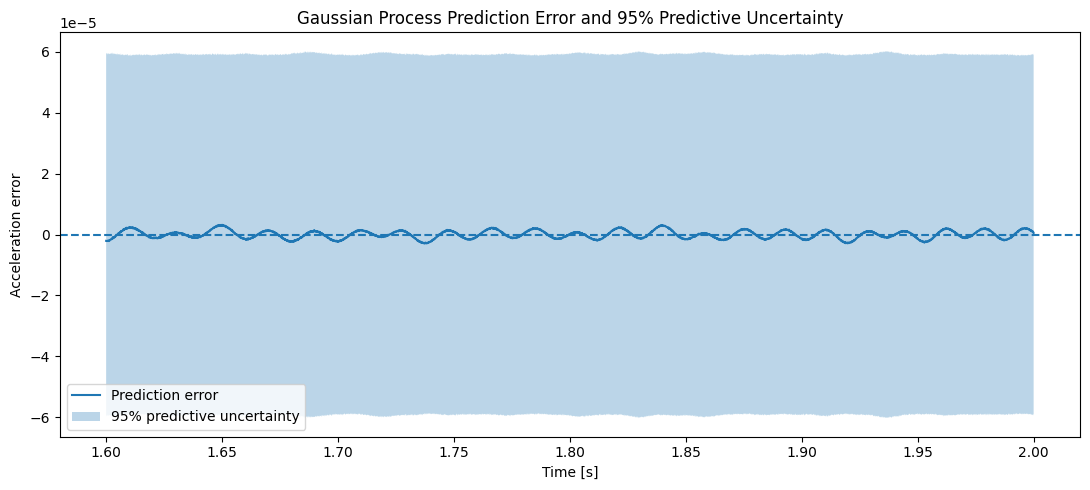

GP error and uncertainty figure saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\figures\probabilistic_ml\gaussian_process_error_uncertainty.png


In [8]:
# PLOT PREDICTION ERROR WITH 95% UNCERTAINTY BOUNDS


# Prediction error:
#
# true acceleration - predictive mean

gp_test_error = (
    y_test_gp
    - gp_test_mean
)


# Express the 95% uncertainty interval relative to
# the predictive mean.
#
# Since the mean itself becomes zero in an error plot,
# the uncertainty limits are simply ±1.96 sigma.

gp_error_lower_95 = (
    -1.96
    * gp_test_std
)

gp_error_upper_95 = (
    1.96
    * gp_test_std
)


plt.figure(
    figsize=(11, 5)
)


# Plot the actual GP prediction error.
plt.plot(
    time_test_gp,
    gp_test_error,
    label="Prediction error",
)


# Plot the 95% uncertainty region around zero.
plt.fill_between(
    time_test_gp,
    gp_error_lower_95,
    gp_error_upper_95,
    alpha=0.30,
    label="95% predictive uncertainty",
)


# Zero-error reference line.
plt.axhline(
    0.0,
    linestyle="--",
)


plt.xlabel(
    "Time [s]"
)

plt.ylabel(
    "Acceleration error"
)

plt.title(
    "Gaussian Process Prediction Error "
    "and 95% Predictive Uncertainty"
)

plt.legend()

plt.tight_layout()


# Save the figure.
gp_error_uncertainty_figure_path = (
    probabilistic_figure_directory
    / "gaussian_process_error_uncertainty.png"
)

plt.savefig(
    gp_error_uncertainty_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "GP error and uncertainty figure saved to:"
)

print(
    gp_error_uncertainty_figure_path
)

### Prediction Error and Predictive Uncertainty

The error-scale visualization makes the Gaussian Process uncertainty much easier to inspect than the full acceleration plot.

The prediction error remains very close to zero across the complete held-out interval, with a magnitude substantially smaller than the 95% predictive uncertainty bounds.

The uncertainty interval has an approximate half-width of

$$
6\times10^{-5},
$$

whereas the actual prediction errors are mostly on the order of

$$
10^{-6}.
$$

Consequently, all held-out observations remain inside the nominal 95% predictive interval.

This confirms that the Gaussian Process is highly accurate for the deterministic baseline, but also indicates that its uncertainty estimate is conservative relative to the observed prediction error.

In [9]:
# QUANTIFY PREDICTIVE-INTERVAL WIDTH

# Calculate the width of the nominal 95% predictive interval.
gp_interval_width_95 = (
    gp_upper_95
    - gp_lower_95
)


# Mean and maximum interval width.
gp_mean_interval_width_95 = np.mean(
    gp_interval_width_95
)

gp_max_interval_width_95 = np.max(
    gp_interval_width_95
)


# Compare typical prediction error with typical uncertainty.
mean_absolute_gp_error = np.mean(
    np.abs(
        gp_test_error
    )
)


uncertainty_to_error_ratio = (
    gp_mean_predictive_std
    / mean_absolute_gp_error
)


print(
    f"Mean 95% interval width: "
    f"{gp_mean_interval_width_95:.12e}"
)

print(
    f"Maximum 95% interval width: "
    f"{gp_max_interval_width_95:.12e}"
)

print()

print(
    f"Mean absolute GP error: "
    f"{mean_absolute_gp_error:.12e}"
)

print(
    f"Mean predictive std / mean absolute error: "
    f"{uncertainty_to_error_ratio:.6f}"
)

Mean 95% interval width: 1.185212210459e-04
Maximum 95% interval width: 1.207780792427e-04

Mean absolute GP error: 1.104566757868e-06
Mean predictive std / mean absolute error: 27.372728


### Quantitative Assessment of Uncertainty Conservativeness

The mean width of the nominal 95% predictive interval was approximately

$$
1.19\times10^{-4},
$$

while the mean absolute prediction error was only approximately

$$
1.10\times10^{-6}.
$$

The mean predictive standard deviation was approximately 27 times larger than the mean absolute prediction error.

This confirms quantitatively that the Gaussian Process uncertainty estimate is conservative for the deterministic baseline.

The result is not unexpected because the underlying data are noise-free and generated from a smooth deterministic system. In such a setting, the predictive mean can be extremely accurate while the probabilistic model still retains a small non-zero uncertainty estimate.

In [10]:
# CREATE A CONTROLLED NOISY ACCELERATION TARGET

# Use the same reproducible project seed.
noise_rng = np.random.default_rng(
    9512
)


# Controlled acceleration-noise standard deviation.
acceleration_noise_std = 0.05


# Generate noise for the complete deterministic trajectory.
acceleration_noise = noise_rng.normal(
    loc=0.0,
    scale=acceleration_noise_std,
    size=len(gp_target),
)


# Add noise to the deterministic acceleration.
noisy_gp_target = (
    gp_target
    + acceleration_noise
)


# Use the SAME time-aware split as before.
y_train_full_noisy = noisy_gp_target[
    :split_index
]

y_test_gp_noisy = noisy_gp_target[
    split_index:
]


# Use the SAME 800 evenly spaced training indices.
y_train_gp_noisy = y_train_full_noisy[
    gp_training_indices
]



# CHECK THE REALIZED NOISE
realized_noise_mean = np.mean(
    acceleration_noise
)

realized_noise_std = np.std(
    acceleration_noise
)


print(
    f"Requested noise standard deviation: "
    f"{acceleration_noise_std:.6f}"
)

print(
    f"Realized noise mean: "
    f"{realized_noise_mean:.6f}"
)

print(
    f"Realized noise standard deviation: "
    f"{realized_noise_std:.6f}"
)

print()

print(
    f"Noisy GP training targets: "
    f"{len(y_train_gp_noisy)}"
)

print(
    f"Noisy GP test targets:     "
    f"{len(y_test_gp_noisy)}"
)

Requested noise standard deviation: 0.050000
Realized noise mean: -0.000067
Realized noise standard deviation: 0.049848

Noisy GP training targets: 800
Noisy GP test targets:     4001


In [11]:
# STANDARDIZE THE NOISY TARGET


# Create a new scaler specifically for the noisy
# acceleration target.
noisy_gp_target_scaler = StandardScaler()


# Fit the scaler ONLY using the noisy GP training targets.
y_train_gp_noisy_scaled = (
    noisy_gp_target_scaler
    .fit_transform(
        y_train_gp_noisy.reshape(-1, 1)
    )
    .ravel()
)


print(
    f"Scaled noisy target mean: "
    f"{np.mean(y_train_gp_noisy_scaled):.12e}"
)

print(
    f"Scaled noisy target standard deviation: "
    f"{np.std(y_train_gp_noisy_scaled):.12f}"
)



# DEFINE THE NOISY GAUSSIAN PROCESS

# We use the same general kernel structure as before so
# that the deterministic and noisy GP experiments remain
# directly comparable.

noisy_gp_kernel = (
    ConstantKernel(
        constant_value=1.0,
        constant_value_bounds=(1e-3, 1e3),
    )
    *
    RBF(
        length_scale=[
            1.0,
            1.0,
            1.0,
        ],
        length_scale_bounds=(1e-2, 1e3),
    )
    +
    WhiteKernel(
        noise_level=1e-4,
        noise_level_bounds=(1e-8, 1e-1),
    )
)


noisy_gaussian_process_model = GaussianProcessRegressor(
    kernel=noisy_gp_kernel,
    alpha=0.0,
    normalize_y=False,
    n_restarts_optimizer=2,
    random_state=9512,
)



# TRAIN THE NOISY GAUSSIAN PROCESS

noisy_gaussian_process_model.fit(
    X_train_gp_scaled,
    y_train_gp_noisy_scaled,
)


print()

print(
    "Optimized noisy Gaussian Process kernel:"
)

print(
    noisy_gaussian_process_model.kernel_
)

print()

print(
    "Noisy GP log-marginal likelihood:"
)

print(
    f"{noisy_gaussian_process_model.log_marginal_likelihood_value_:.6f}"
)

Scaled noisy target mean: -3.774758283726e-17
Scaled noisy target standard deviation: 1.000000000000

Optimized noisy Gaussian Process kernel:
31.6**2 * RBF(length_scale=[64.9, 1e+03, 204]) + WhiteKernel(noise_level=0.000282)

Noisy GP log-marginal likelihood:
2102.997492


c:\Users\ahmed\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\ahmed\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


In [12]:
# CONVERT THE LEARNED GP NOISE LEVEL TO PHYSICAL UNITS

# Extract the optimized WhiteKernel variance.
#
# Kernel structure:
#
# ConstantKernel * RBF + WhiteKernel
#
# Therefore the WhiteKernel is k2.

learned_noise_variance_scaled = (
    noisy_gaussian_process_model
    .kernel_
    .k2
    .noise_level
)


# Convert variance to standard deviation in standardized units.
learned_noise_std_scaled = np.sqrt(
    learned_noise_variance_scaled
)


# Convert the standard deviation back to physical
# acceleration units.
learned_noise_std_physical = (
    learned_noise_std_scaled
    * noisy_gp_target_scaler.scale_[0]
)


# Compare with the true injected noise level.
noise_std_absolute_error = abs(
    learned_noise_std_physical
    - acceleration_noise_std
)

noise_std_relative_error = (
    noise_std_absolute_error
    / acceleration_noise_std
    * 100.0
)


print(
    f"Learned noise variance "
    f"(standardized units): "
    f"{learned_noise_variance_scaled:.12e}"
)

print(
    f"Learned noise std "
    f"(standardized units): "
    f"{learned_noise_std_scaled:.12e}"
)

print()

print(
    f"Learned noise std "
    f"(physical units): "
    f"{learned_noise_std_physical:.6f}"
)

print(
    f"True injected noise std: "
    f"{acceleration_noise_std:.6f}"
)

print()

print(
    f"Absolute noise-std error: "
    f"{noise_std_absolute_error:.6f}"
)

print(
    f"Relative noise-std error: "
    f"{noise_std_relative_error:.4f}%"
)

Learned noise variance (standardized units): 2.821143122392e-04
Learned noise std (standardized units): 1.679625887629e-02

Learned noise std (physical units): 0.050232
True injected noise std: 0.050000

Absolute noise-std error: 0.000232
Relative noise-std error: 0.4643%


In [13]:
# NOISY GAUSSIAN PROCESS PREDICTION


# Predict the noisy held-out test data.
#
# The model returns:
#
# 1. predictive mean in standardized target units,
# 2. predictive standard deviation in standardized units.

(
    noisy_gp_test_mean_scaled,
    noisy_gp_test_std_scaled,
) = noisy_gaussian_process_model.predict(
    X_test_gp_scaled,
    return_std=True,
)


# TRANSFORM PREDICTIONS BACK TO PHYSICAL UNITS
noisy_gp_test_mean = (
    noisy_gp_target_scaler
    .inverse_transform(
        noisy_gp_test_mean_scaled.reshape(-1, 1)
    )
    .ravel()
)


noisy_gp_test_std = (
    noisy_gp_test_std_scaled
    * noisy_gp_target_scaler.scale_[0]
)


# CONSTRUCT APPROXIMATE 95% PREDICTION INTERVALS
noisy_gp_lower_95 = (
    noisy_gp_test_mean
    - 1.96 * noisy_gp_test_std
)

noisy_gp_upper_95 = (
    noisy_gp_test_mean
    + 1.96 * noisy_gp_test_std
)



# EVALUATE AGAINST THE NOISY TEST OBSERVATIONS
noisy_gp_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_gp_noisy,
        noisy_gp_test_mean,
    )
)

noisy_gp_test_mae = mean_absolute_error(
    y_test_gp_noisy,
    noisy_gp_test_mean,
)

noisy_gp_test_r2 = r2_score(
    y_test_gp_noisy,
    noisy_gp_test_mean,
)



# UNCERTAINTY STATISTICS
noisy_gp_mean_predictive_std = np.mean(
    noisy_gp_test_std
)

noisy_gp_max_predictive_std = np.max(
    noisy_gp_test_std
)


# Empirical coverage of the nominal 95% interval.
noisy_gp_coverage_95 = np.mean(
    (y_test_gp_noisy >= noisy_gp_lower_95)
    &
    (y_test_gp_noisy <= noisy_gp_upper_95)
)


print(
    f"Noisy GP testing RMSE: "
    f"{noisy_gp_test_rmse:.6f}"
)

print(
    f"Noisy GP testing MAE:  "
    f"{noisy_gp_test_mae:.6f}"
)

print(
    f"Noisy GP testing R²:   "
    f"{noisy_gp_test_r2:.12f}"
)

print()

print(
    f"Mean predictive standard deviation: "
    f"{noisy_gp_mean_predictive_std:.6f}"
)

print(
    f"Maximum predictive standard deviation: "
    f"{noisy_gp_max_predictive_std:.6f}"
)

print(
    f"95% interval empirical coverage: "
    f"{100 * noisy_gp_coverage_95:.4f}%"
)

Noisy GP testing RMSE: 0.050365
Noisy GP testing MAE:  0.040100
Noisy GP testing R²:   0.999780449478

Mean predictive standard deviation: 0.050474
Maximum predictive standard deviation: 0.050752
95% interval empirical coverage: 94.8513%


### Noisy Gaussian Process Performance and Calibration

The Gaussian Process was next evaluated using acceleration measurements with controlled Gaussian noise of standard deviation

$$
\sigma_{\epsilon}=0.05.
$$

The resulting test RMSE was

$$
0.05037,
$$

which is close to the magnitude of the injected measurement noise.

The model retained a very high predictive coefficient of determination:

$$
R^2\approx0.99978.
$$

More importantly, the mean predictive standard deviation was

$$
0.05047,
$$

which closely matches the true injected noise standard deviation.

The nominal 95% predictive interval achieved an empirical coverage of

$$
94.85\%.
$$

This is very close to the theoretical target of 95%, indicating that the probabilistic predictions are well calibrated for the controlled noisy experiment.

The result demonstrates that the Gaussian Process is able not only to predict the underlying dynamical response accurately, but also to quantify the magnitude of measurement uncertainty.

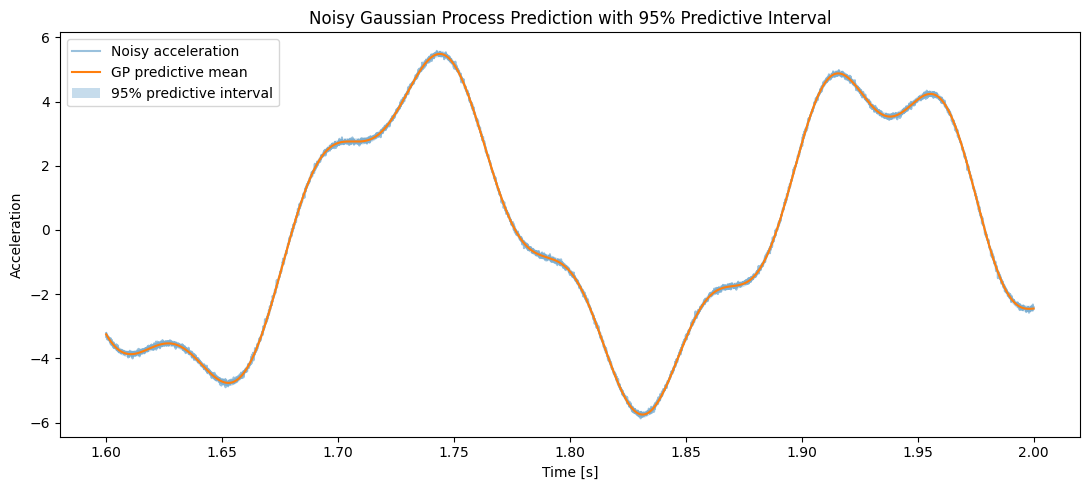

Noisy Gaussian Process prediction figure saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\figures\probabilistic_ml\noisy_gaussian_process_prediction_interval.png


In [14]:
# PLOT NOISY GP PREDICTION AND 95% INTERVAL


plt.figure(
    figsize=(11, 5)
)


# Noisy observations.
plt.plot(
    time_test_gp,
    y_test_gp_noisy,
    label="Noisy acceleration",
    alpha=0.45,
)


# GP predictive mean.
plt.plot(
    time_test_gp,
    noisy_gp_test_mean,
    label="GP predictive mean",
)


# 95% predictive interval.
plt.fill_between(
    time_test_gp,
    noisy_gp_lower_95,
    noisy_gp_upper_95,
    alpha=0.25,
    label="95% predictive interval",
)


plt.xlabel(
    "Time [s]"
)

plt.ylabel(
    "Acceleration"
)

plt.title(
    "Noisy Gaussian Process Prediction "
    "with 95% Predictive Interval"
)

plt.legend()

plt.tight_layout()


# Save the figure.
noisy_gp_prediction_figure_path = (
    probabilistic_figure_directory
    / "noisy_gaussian_process_prediction_interval.png"
)

plt.savefig(
    noisy_gp_prediction_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "Noisy Gaussian Process prediction figure saved to:"
)

print(
    noisy_gp_prediction_figure_path
)

### Noisy Gaussian Process Prediction Interval

The noisy Gaussian Process predictive mean follows the underlying dynamical response while filtering the random fluctuations present in the noisy acceleration observations.

The 95% predictive interval is clearly visible in this experiment because the uncertainty level is comparable to the injected measurement-noise scale.

The interval contains approximately

$$
94.85\%
$$

of the held-out noisy observations, which is very close to the nominal 95% coverage level.

This visual result supports the quantitative calibration analysis and demonstrates that the probabilistic model successfully separates the smooth dynamical response from measurement uncertainty.

In [16]:
# CREATE PROBABILISTIC-ML RESULT SUMMARY
probabilistic_model_comparison = pd.DataFrame(
    {
        "experiment": [
            "Deterministic GP",
            "Noisy GP",
        ],

        "testing_rmse": [
            gp_test_rmse,
            noisy_gp_test_rmse,
        ],

        "testing_mae": [
            gp_test_mae,
            noisy_gp_test_mae,
        ],

        "testing_r2": [
            gp_test_r2,
            noisy_gp_test_r2,
        ],

        "mean_predictive_std": [
            gp_mean_predictive_std,
            noisy_gp_mean_predictive_std,
        ],

        "coverage_95_percent": [
            100.0 * gp_coverage_95,
            100.0 * noisy_gp_coverage_95,
        ],
    }
)


probabilistic_model_comparison

,experiment,testing_rmse,testing_mae,testing_r2,mean_predictive_std,coverage_95_percent
0,Deterministic GP,0.000001,0.000001,1.00000,0.000030,100.000000
1,Noisy GP,0.050365,0.040100,0.99978,0.050474,94.851287


In [17]:
# SAVE PROBABILISTIC-ML RESULTS
probabilistic_results_directory = results_path(
    "probabilistic_ml"
)

ensure_directory(
    probabilistic_results_directory
)



# SAVE CLEAN VS NOISY GP COMPARISON
probabilistic_comparison_path = (
    probabilistic_results_directory
    / "gaussian_process_experiment_comparison.csv"
)

probabilistic_model_comparison.to_csv(
    probabilistic_comparison_path,
    index=False,
)



# SAVE NOISE-RECOVERY RESULT
gp_noise_recovery = pd.DataFrame(
    {
        "quantity": [
            "Injected noise std",
            "GP learned noise std",
            "Absolute error",
            "Relative error percent",
        ],
        "value": [
            acceleration_noise_std,
            learned_noise_std_physical,
            noise_std_absolute_error,
            noise_std_relative_error,
        ],
    }
)


gp_noise_recovery_path = (
    probabilistic_results_directory
    / "gaussian_process_noise_recovery.csv"
)

gp_noise_recovery.to_csv(
    gp_noise_recovery_path,
    index=False,
)


print(
    "GP experiment comparison saved to:"
)
print(
    probabilistic_comparison_path
)

print()

print(
    "GP noise-recovery results saved to:"
)
print(
    gp_noise_recovery_path
)

GP experiment comparison saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\probabilistic_ml\gaussian_process_experiment_comparison.csv

GP noise-recovery results saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\probabilistic_ml\gaussian_process_noise_recovery.csv


In [18]:
# VERIFY REUSABLE PROBABILISTIC FUNCTIONS

from src.probabilistic_models import (
    calculate_prediction_interval,
    calculate_interval_coverage,
    extract_gp_noise_std,
)


# Recreate the 95% interval using the reusable function.
(
    noisy_gp_lower_95_check,
    noisy_gp_upper_95_check,
) = calculate_prediction_interval(
    noisy_gp_test_mean,
    noisy_gp_test_std,
)


# Recalculate empirical coverage.
noisy_gp_coverage_check = calculate_interval_coverage(
    y_test_gp_noisy,
    noisy_gp_lower_95_check,
    noisy_gp_upper_95_check,
)


# Re-extract the learned physical noise standard deviation.
learned_noise_std_check = extract_gp_noise_std(
    noisy_gaussian_process_model,
    noisy_gp_target_scaler,
)


print(
    f"Reusable-function 95% coverage: "
    f"{100 * noisy_gp_coverage_check:.4f}%"
)

print(
    f"Reusable-function learned noise std: "
    f"{learned_noise_std_check:.6f}"
)

Reusable-function 95% coverage: 94.8513%
Reusable-function learned noise std: 0.050232


In [19]:
# FINAL OUTPUT VALIDATION FOR NOTEBOOK 08

notebook_08_outputs = {
    "gp_experiment_comparison":
        probabilistic_comparison_path,

    "gp_noise_recovery":
        gp_noise_recovery_path,

    "clean_gp_prediction_figure":
        gp_prediction_figure_path,

    "clean_gp_uncertainty_figure":
        gp_uncertainty_figure_path,

    "clean_gp_error_uncertainty_figure":
        gp_error_uncertainty_figure_path,

    "noisy_gp_prediction_figure":
        noisy_gp_prediction_figure_path,
}


for output_name, output_path in notebook_08_outputs.items():

    print(
        f"{output_name:40s} "
        f"{output_path.exists()}"
    )

gp_experiment_comparison                 True
gp_noise_recovery                        True
clean_gp_prediction_figure               True
clean_gp_uncertainty_figure              True
clean_gp_error_uncertainty_figure        True
noisy_gp_prediction_figure               True


# Notebook 08 Summary

This notebook extended the deterministic machine-learning analysis to probabilistic prediction using Gaussian Process Regression.

The objective was not only to predict acceleration,

$$
\hat{\ddot{x}},
$$

but also to quantify predictive uncertainty through a conditional distribution,

$$
p(\ddot{x}\mid x,\dot{x},F).
$$

## Deterministic Gaussian Process

The Gaussian Process was first trained on the deterministic baseline using an evenly spaced subset of 800 training samples.

The input variables and acceleration target were standardized before model fitting.

The deterministic GP achieved highly accurate held-out predictions:

$$
\mathrm{RMSE}\approx1.30\times10^{-6},
$$

$$
\mathrm{MAE}\approx1.10\times10^{-6},
$$

with

$$
R^2=1.000000.
$$

The mean predictive standard deviation was approximately

$$
3.02\times10^{-5}.
$$

The nominal 95% predictive interval contained 100% of the test observations.

Although the predictions were extremely accurate, the uncertainty interval was conservative relative to the actual prediction error. The predictive standard deviation was approximately 27 times larger than the mean absolute prediction error.

## Controlled Noisy Experiment

A second experiment introduced Gaussian acceleration noise with

$$
\sigma_{\epsilon}=0.05.
$$

The realized noise standard deviation was approximately

$$
0.04985.
$$

The Gaussian Process learned an observation-noise standard deviation of

$$
0.050232,
$$

corresponding to a relative error of only

$$
0.4643\%.
$$

This demonstrates that the probabilistic model was able to recover the magnitude of the injected measurement uncertainty.

## Noisy Predictive Performance

For the noisy held-out test data, the GP achieved

$$
\mathrm{RMSE}\approx0.05037,
$$

$$
\mathrm{MAE}\approx0.04010,
$$

and

$$
R^2\approx0.99978.
$$

The mean predictive standard deviation was

$$
0.05047,
$$

which closely matched the true measurement-noise scale.

The nominal 95% predictive interval achieved empirical coverage of

$$
94.85\%.
$$

This is very close to the theoretical 95% target and indicates strong probabilistic calibration.

## Main Finding

The deterministic experiment showed that Gaussian Process Regression can provide highly accurate predictions with very small uncertainty for clean system data.

More importantly, the controlled noisy experiment demonstrated that the GP can recover the magnitude of measurement uncertainty and produce well-calibrated predictive intervals.

The learned noise standard deviation of approximately

$$
0.05023
$$

closely matched the injected value of

$$
0.05,
$$

while the 95% predictive interval achieved approximately

$$
94.85\%
$$

empirical coverage.

These results provide a probabilistic uncertainty baseline that will later be compared with Monte Carlo uncertainty propagation and physics-informed modelling.